This notebook ('diann_protein_group_abundance_rank.ipynb') reads and filters the main report from DIANN output (report.parquet), selects runs for defined conditions, and compares the dynamic range of quantified protein group abundances (PG.MaxLFQ) across conditions via rank-abundance ("waterfall") plots.
Results are exported as individual .csv files per flush mode together with rank-abundance plots (PNG and SVG) visualizing log10 abundance vs. rank per condition.

**Workflow overview:**

1. **Setup** – Import packages, set working directory, import custom `diann_main_report_filtering` and `retention_time_stability_stats` modules, enable autoreload, configure pandas display options.
2. **Define paths** – Set `input_dir` / `output_dir` for the dataset to process.
3. **Load report** – Read DIA-NN's `report.parquet` into a pandas DataFrame.
4. **FDR filtering** – Sequentially filter the main report at 1% precursor Q.Value (run-specific and global) and 1% global protein group Q.Value, plus a lenient Quantity.Quality cutoff (≥ 0.5).
5. **Run selection** – Define forward and reverse flush run lists per condition (pepmap, nanoshield_tht021_flip, direct_injection) and subset the filtered report into `main_report_pd_fil_for` / `main_report_pd_fil_rev`.
6. **Condition assignment & proteotypic filtering** – Map acquisition dates to condition names, then retain only proteotypic protein groups with a valid, non-zero PG.MaxLFQ value.
7. **Per-condition completeness filtering** – Retain only protein groups quantified in all replicates within their own condition (no cross-condition requirement) and remove cRAP entries.
8. **Rank-abundance table** – Average PG.MaxLFQ across replicates per protein group per condition, rank descending (rank 1 = highest abundance) within each condition, and log10-transform the abundance.
9. **Export & plot** – For each flush mode (forward, reverse), export the rank-abundance table as `.csv` and generate/save a rank-abundance plot (log10 abundance vs. rank, PNG and SVG) with one line per condition.

In [1]:
# import relevant packages
import sys
import os
import inspect
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from textwrap import dedent

# change working direction - point to where your notebooks (.ipynb) and python files (.py) are placed
new_cwd = Path("Z:/user/Dennis/trap_column_test/manuscript/diann_processing/jupyter_notebooks/github/")
os.chdir(new_cwd)
# verify new working directory
print("Current working directory:\n",os.getcwd())

# import custom functions
import diann_main_report_filtering as diann_filter
import retention_time_stability_stats as rts

# auto reload of imported packages
%load_ext autoreload
%autoreload 2

# check where python is looking for path to resolve imports and where it actually loaded the packages from
print(f"This is where python is looking for packages:\n{sys.path}\n")

# change display settings for pandas dataframes
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)

# set to back to default if needed
#pd.reset_option("display.max_columns")
#pd.reset_option("display.max_rows")
    
# check current working directory of this notebook
print("Current working directory:")
!pwd

Current working directory:
 Z:\user\Dennis\trap_column_test\manuscript\diann_processing\jupyter_notebooks\github
This is where python is looking for packages:
['C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\python313.zip', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\DLLs', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test', '', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages\\win32', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages\\win32\\lib', 'C:\\Users\\dennis.dannecker\\AppData\\Local\\anaconda3\\envs\\trap_column_test\\Lib\\site-packages\\Pythonwin']

Current working directory:
/z/user/Dennis/t

In [2]:
# define input and output directories for each acquired dataset

input_dir = Path("Z:/user/Dennis/trap_column_test/manuscript/diann_processing/dataset_g_combined/")
output_dir = Path("Z:/user/Dennis/trap_column_test/manuscript/diann_processing/dataset_g_combined/github_test/protein_group_abundance_rank/")

In [3]:
# read dianns main output parquet file as a pandas dataframe

# define input file name
input_file_name = "report.parquet"
# define input file path
input_file_path = input_dir / input_file_name
# read parquet file as pd dataframe
main_report_pd = pd.read_parquet(input_file_path, engine='pyarrow')
print("DIANN's parquet file was read in as a pandas dataframe.")

DIANN's parquet file was read in as a pandas dataframe.


In [4]:
# perform basic FDR filtering of loaded main report, "main_report_pd"

# filters sequentially, overwriting the variable to save memory
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd, column="Q.Value", cutoff=0.01, smaller_than=True, filter_proteotypic=False) # default precursor filtering at 1%, run-specific
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd_fil, column="Global.Q.Value", cutoff=0.01, smaller_than=True, filter_proteotypic=False) # precursor filtering at 1%, global
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd_fil, column="Global.PG.Q.Value", cutoff=0.01, smaller_than=True, filter_proteotypic=False) # protein group filtering at 1%, global
# lenient, retain the vast majority of IDs, drop only clearly bad ones - quality of precursor quantity, is it trustworthy
main_report_pd_fil = diann_filter.filter_dataframe(df=main_report_pd_fil, column="Quantity.Quality", cutoff=0.5, smaller_than=False, filter_proteotypic=False)
# reset index after filtering to maintain a clean sequence
main_report_pd_fil.reset_index(drop=True, inplace=True)
print("Dataframe was filtered successfully")

Dataframe was filtered successfully


In [5]:
# higher level conditions and run selection

# define selected runs
run_sel_for = [
  # pepmap - forward
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_1",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_2",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_3",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_4",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_5",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_for_6",
  # nanoshield tht021 flipped - forward
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_1",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_2",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_3",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_4",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_5",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_for_6",
  # direct injection
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_1",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_2",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_3",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_4",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_5",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_6", 
]

run_sel_rev = [
  # pepmap - reverse
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_1",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_2",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_3",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_4",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_5",
  "20260911_N2A1_TH103_DD_THIDTrapTestG_pep_QCdia250_rev_6",
  # nanoshield tht021 flipped - reverse
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_1",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_2",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_3",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_4",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_5",
  "20260914_N2A1_TH103_DD_THIDTrapTestG_cc1_tht021_flip_QCdia250_rev_6",
  # direct injection
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_1",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_2",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_3",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_4",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_5",
  "20260916_N2A1_TH103_DD_THIDTrapTestG_cc1_di_QCdia250_6", 
]

# select runs from main report using exact matching for "Run" name - main_report_pd_fil_for is main dataframe used for all analyses below - forward
main_report_pd_fil_for = main_report_pd_fil[main_report_pd_fil["Run"].isin(run_sel_for)].copy()
print("Selection is done - forward")
# select runs from main report using exact matching for "Run" name - main_report_pd_fil_rev is main dataframe used for all analyses below - reverse
main_report_pd_fil_rev = main_report_pd_fil[main_report_pd_fil["Run"].isin(run_sel_rev)].copy()
print("Selection is done - reverse")

Selection is done - forward
Selection is done - reverse


Rank-abundance data exported for forward and reverse flush mode.


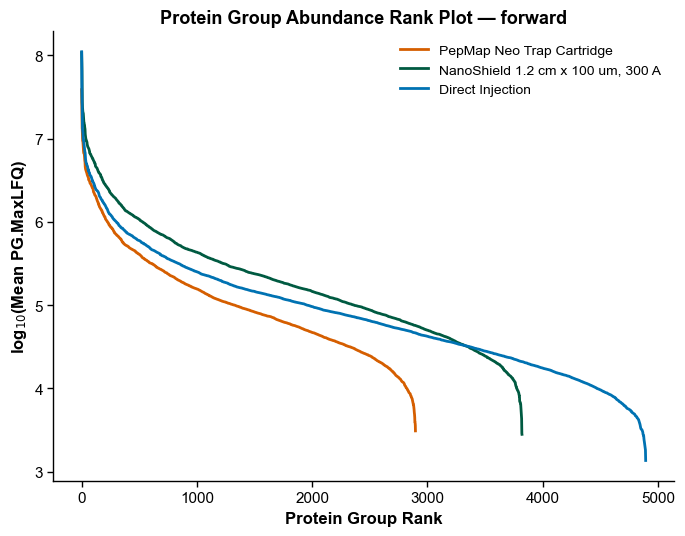

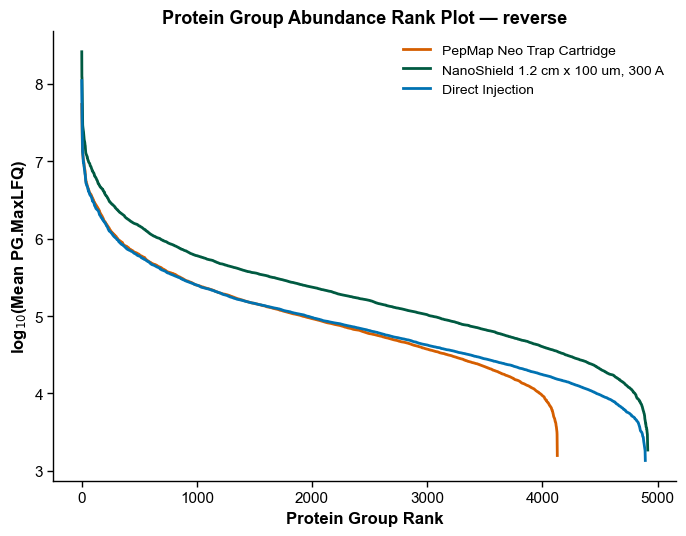

In [6]:
# ══════════════════════════════════════════════════════════════════════════════
# PROTEIN GROUP ABUNDANCE RANK PLOT ("waterfall" / rank-abundance plot)
# ══════════════════════════════════════════════════════════════════════════════
#
# Purpose:
#   Compare the DYNAMIC RANGE of quantified protein group abundances (PG.MaxLFQ)
#   across the three conditions of interest:
#     - pepmap                  (PepMap Neo Trap Cartridge)
#     - nanoshield_tht021_flip  (NanoShield 1.2 cm x 100 um, 300 A)
#     - direct_injection        (Direct Injection)
#
# Metric:
#   Same abundance metric used for the CV analysis -> PG.MaxLFQ, restricted to
#   proteotypic protein groups with a valid (non-zero, non-null) value.
#
# Filtering:
#   Per-condition-only completeness filter (same helper logic as the CV
#   analysis): a protein group must be quantified in ALL replicates WITHIN its
#   own condition to be included for that condition. No cross-condition
#   completeness requirement is imposed, since each condition's rank curve is
#   describing its own dynamic range independently.
#
# Per protein group / condition, the mean PG.MaxLFQ across replicates is taken
# as its representative abundance, then ranked in descending order (rank 1 =
# highest abundance) separately per condition.
#
# Output:
#   - One rank plot for "forward" and one for "reverse" flush mode, each
#     showing all three condition curves (log10 abundance vs. rank).
#   - Underlying long-form data exported as .csv (one file per flush mode) for
#     external plotting in GraphPad.
# ══════════════════════════════════════════════════════════════════════════════

# conditions of interest for this analysis (subset of the full condition_config)
rank_conditions = ["pepmap", "nanoshield_tht021_flip", "direct_injection"]

# mapping from acquisition date prefix to condition name (same as CV analysis)
date_to_condition = {
    "20260911": "pepmap",
    "20260914": "nanoshield_tht021_flip",
    "20260916": "direct_injection",
}

def filter_complete_within_condition_only(df):
    """Keep (Condition, Protein.Group) pairs complete in ALL replicates of their own condition."""
    req_counts = df.groupby("Condition")["Run"].nunique()
    pg_counts = df.groupby(["Condition", "Protein.Group"])["Run"].nunique().reset_index(name="n_runs")
    pg_counts["required"] = pg_counts["Condition"].map(req_counts)
    complete_pairs = pg_counts[pg_counts["n_runs"] == pg_counts["required"]]
    valid_pairs = set(zip(complete_pairs["Condition"], complete_pairs["Protein.Group"]))
    mask = df.apply(lambda row: (row["Condition"], row["Protein.Group"]) in valid_pairs, axis=1)
    return df[mask].copy()


def build_rank_abundance_table(df_fil, date_to_condition, conditions_of_interest):
    """
    Build the per-condition rank-abundance table for the protein group
    abundance rank plot.

    Steps:
      1. assign Condition from Run prefix, restrict to conditions of interest
      2. restrict to proteotypic PGs with a valid PG.MaxLFQ value
      3. filter for PGs complete in all replicates within their own condition
      4. drop cRAP protein groups
      5. average PG.MaxLFQ across replicates per (Condition, Protein.Group)
      6. rank descending (rank 1 = highest abundance) within each condition
    """
    df = df_fil.copy()
    df["Condition"] = df["Run"].astype(str).str[:8].map(date_to_condition)
    df = df[df["Condition"].isin(conditions_of_interest)]

    # proteotypic + valid quantity value
    df = df[df["Proteotypic"] == 1]
    df = df[(df["PG.MaxLFQ"] != 0) & (df["PG.MaxLFQ"].notna())]

    # per-condition replicate-completeness filter
    df = filter_complete_within_condition_only(df)

    # drop cRAP entries
    df = df[~df["Protein.Group"].str.contains("cRAP", case=False, na=False)]

    # average abundance across replicates per protein group per condition
    pg_abundance = (
        df.groupby(["Condition", "Protein.Group"])["PG.MaxLFQ"]
        .mean()
        .reset_index()
        .rename(columns={"PG.MaxLFQ": "Mean_PG_MaxLFQ"})
    )

    # rank descending within each condition (1 = most abundant)
    pg_abundance["Rank"] = (
        pg_abundance.groupby("Condition")["Mean_PG_MaxLFQ"]
        .rank(method="first", ascending=False)
        .astype(int)
    )

    # log10-transformed abundance for plotting
    pg_abundance["log10_Mean_PG_MaxLFQ"] = np.log10(pg_abundance["Mean_PG_MaxLFQ"])

    # sort for tidy export
    pg_abundance = pg_abundance.sort_values(["Condition", "Rank"]).reset_index(drop=True)
    return pg_abundance


def plot_rank_abundance(rank_df, conditions, flush_label, export=True):
    """
    Plot the protein group abundance rank ("waterfall") plot: log10(mean
    PG.MaxLFQ) on the y-axis vs. rank on the x-axis, one line per condition.
    Colors/labels pulled from rts.condition_config (single source of truth).
    """
    fig, ax = plt.subplots(figsize=(7, 5.5))

    for cond in conditions:
        sub = rank_df[rank_df["Condition"] == cond].sort_values("Rank")
        ax.plot(
            sub["Rank"], sub["log10_Mean_PG_MaxLFQ"],
            color=rts.get_color(cond), linewidth=2.0, label=rts.get_label(cond),
        )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_facecolor("white")
    fig.patch.set_facecolor("white")
    ax.grid(False)

    ax.set_xlabel("Protein Group Rank", fontsize=12, fontweight="semibold")
    ax.set_ylabel(r"log$_{10}$(Mean PG.MaxLFQ)", fontsize=12, fontweight="semibold")
    ax.set_title(f"Protein Group Abundance Rank Plot — {flush_label}", fontsize=13, fontweight="bold")
    ax.legend(frameon=False, fontsize=10)
    fig.tight_layout()

    if export:
        output_dir.mkdir(parents=True, exist_ok=True)
        base_name = f"protein_group_abundance_rank_plot_{flush_label}"
        fig.savefig(output_dir / f"{base_name}.png", dpi=600, bbox_inches="tight")
        fig.savefig(output_dir / f"{base_name}.svg", bbox_inches="tight")

    plt.show()


# ── build tables for forward and reverse flush mode ──────────────────────────
rank_abundance_for = build_rank_abundance_table(main_report_pd_fil_for, date_to_condition, rank_conditions)
rank_abundance_rev = build_rank_abundance_table(main_report_pd_fil_rev, date_to_condition, rank_conditions)

# ── export underlying data as descriptively named .csv files for GraphPad ────
rank_abundance_for.to_csv(output_dir / "protein_group_abundance_rank_data_forward.csv", index=False)
rank_abundance_rev.to_csv(output_dir / "protein_group_abundance_rank_data_reverse.csv", index=False)
print("Rank-abundance data exported for forward and reverse flush mode.")

# ── plot rank-abundance curves ────────────────────────────────────────────────
plot_rank_abundance(rank_abundance_for, rank_conditions, "forward")
plot_rank_abundance(rank_abundance_rev, rank_conditions, "reverse")